# 04 · Detección de pedidos anómalos (Isolation Forest)

**Pregunta de negocio 3:** ¿qué pedidos son sospechosos?

Datos: una fila por pedido (todos los estados), creada con `tabla_pedidos()` de `src/features.py`:
importe, número de líneas, unidades, la cantidad más alta de una línea, el precio cobrado frente al
de catálogo (máximo y mínimo entre sus líneas) y el importe por unidad.

> Requisito: haber ejecutado `python src/generar_datos.py` y `python src/limpieza.py`.
>
> **Regla del notebook:** la lista real de pedidos anómalos (`_verdad_anomalias.csv`) **solo** se usa
> en las secciones 7 y 8, marcadas como **EVALUACIÓN**. Las variables, la transformación, los
> hiperparámetros y el umbral se deciden antes y sin mirarla, como en una empresa real, donde esa
> lista no existe.

## 0. Configuración y carga

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import export_text

# El notebook se ejecuta desde notebooks/: src está en ../src
RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))
from features import tabla_pedidos  # noqa: E402

SEMILLA = 42
CARPETA_IMG = RAIZ / "docs" / "img"
CARPETA_IMG.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
AZUL, NARANJA, VERDE_AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)


def euros(valor, decimales=0):
    """12345.6 -> '12.346 €' (formato español)."""
    texto = f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{texto} €"


def num(valor, decimales=2):
    """1234.567 -> '1.234,57' (número en formato español, sin unidad)."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def pct(valor, decimales=1):
    """0.1234 -> '12,3 %'."""
    return f"{num(100 * valor, decimales)} %"


def guardar(fig, nombre):
    """Guarda la figura en docs/img/anomalias_<nombre>.png.

    metadata={"Software": None} quita la versión de matplotlib del PNG: con los mismos datos,
    el archivo es idéntico byte a byte entre ejecuciones.
    """
    fig.savefig(CARPETA_IMG / f"anomalias_{nombre}.png", dpi=120, bbox_inches="tight",
                metadata={"Software": None})

In [2]:
pedidos = tabla_pedidos()

# Variables del modelo (las de identificación y las de texto quedan fuera)
VARIABLES = ["importe_total", "n_lineas", "unidades_totales", "max_cantidad_linea",
             "ratio_precio_max", "ratio_precio_min", "importe_por_unidad"]
ETIQUETAS = {
    "importe_total": "Importe del pedido (€)",
    "n_lineas": "Nº de líneas (productos distintos)",
    "unidades_totales": "Unidades totales",
    "max_cantidad_linea": "Máx. unidades en una línea",
    "ratio_precio_max": "Precio cobrado / catálogo (máx.)",
    "ratio_precio_min": "Precio cobrado / catálogo (mín.)",
    "importe_por_unidad": "Importe por unidad (€)",
}

print(f"Pedidos: {len(pedidos)} (todos los estados)")
print(f"Desde {pedidos['fecha_pedido'].min().date()} hasta {pedidos['fecha_pedido'].max().date()}")
print(pedidos["estado"].value_counts().to_string())
pedidos[VARIABLES].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(2)

Pedidos: 7297 (todos los estados)
Desde 2024-11-04 hasta 2026-10-31
estado
completado    6541
cancelado      391
devuelto       365


,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
count,7297.00,7297.00,7297.00,7297.00,7297.00,7297.00,7297.00
mean,135.81,1.63,2.79,2.01,1.01,1.00,48.23
std,251.09,1.00,3.18,2.71,0.23,0.15,38.35
min,4.97,1.00,1.00,1.00,0.11,0.10,2.68
25%,44.08,1.00,1.00,1.00,1.00,1.00,25.32
50%,83.90,1.00,2.00,2.00,1.00,1.00,39.67
75%,167.71,2.00,4.00,2.00,1.00,1.00,58.92
99%,813.90,4.00,10.00,5.00,1.00,1.00,217.23
max,11730.42,12.00,59.00,59.00,9.58,8.96,572.90


In [3]:
# ¿Cuántos pedidos tienen alguna línea con un precio distinto al de catálogo?
# (se mira con un margen de 0,1 % por los redondeos de la limpieza al recalcular precios)
precio_distinto = ((pedidos["ratio_precio_max"] - 1).abs() > 0.001) | ((pedidos["ratio_precio_min"] - 1).abs() > 0.001)
print(f"Pedidos con alguna línea a un precio distinto del de catálogo: {precio_distinto.sum()} "
      f"({pct(precio_distinto.mean(), 2)})")
print(f"  por encima (ratio máx. > 1,001): {(pedidos['ratio_precio_max'] > 1.001).sum()}")
print(f"  por debajo (ratio mín. < 0,999): {(pedidos['ratio_precio_min'] < 0.999).sum()}")
asimetria = pedidos[VARIABLES].skew().rename("asimetría")
asimetria.round(2).to_frame().T

Pedidos con alguna línea a un precio distinto del de catálogo: 27 (0,37 %)
  por encima (ratio máx. > 1,001): 8
  por debajo (ratio mín. < 0,999): 19


,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
asimetría,24.92,3.07,9.5,14.84,31.17,44.91,3.05


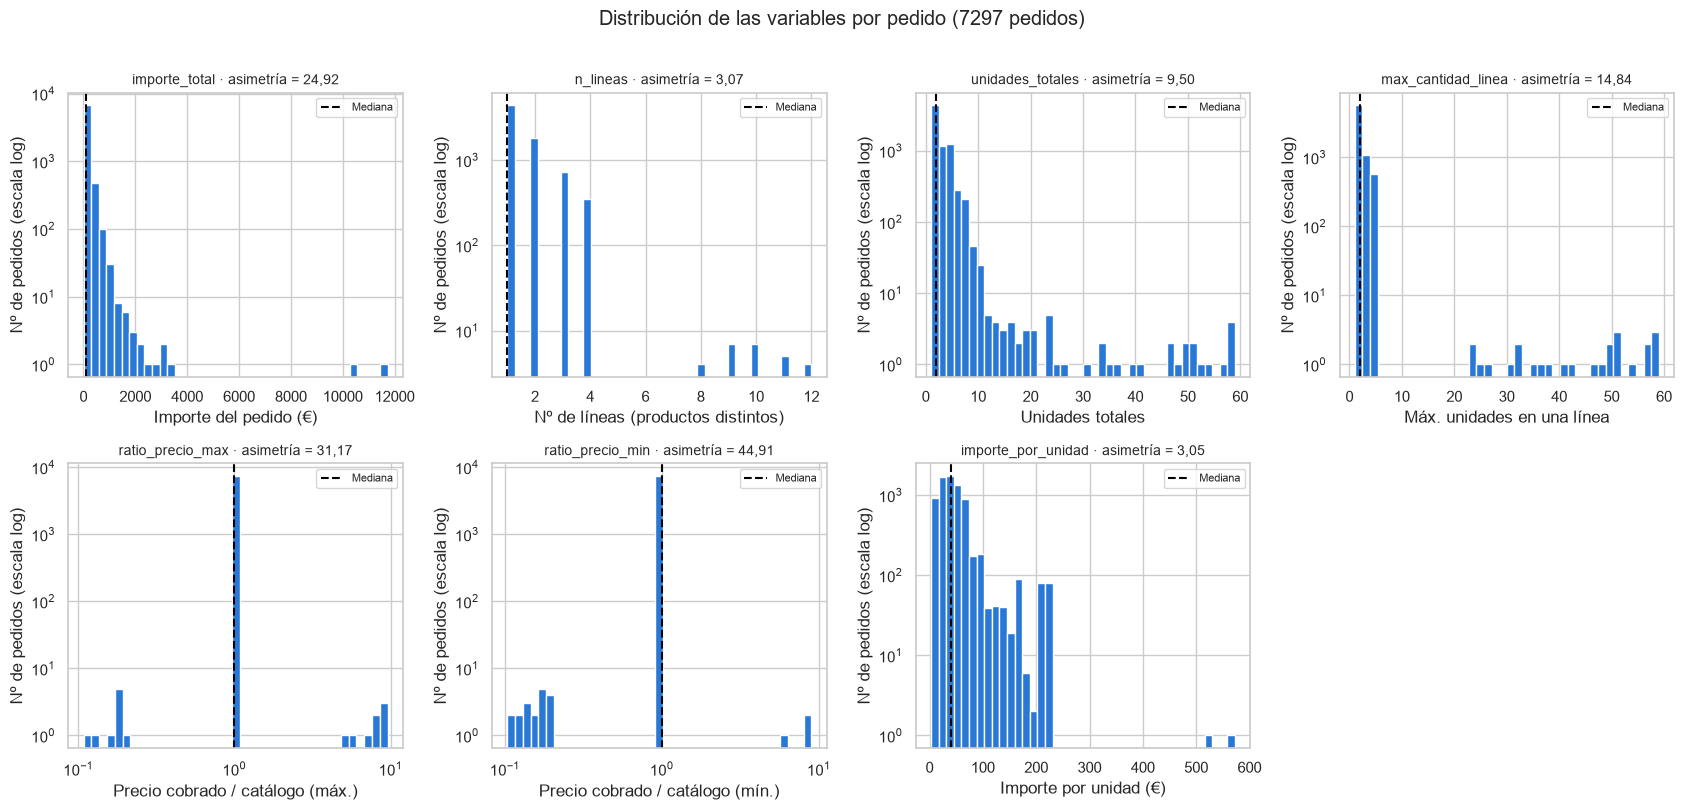

In [4]:
fig, ejes = plt.subplots(2, 4, figsize=(17, 8))
for ax, var in zip(ejes.flat, VARIABLES):
    datos = pedidos[var]
    if var.startswith("ratio"):
        # Los ratios se ven mejor en escala logarítmica: ×10 y ×0,1 quedan a la misma distancia de 1
        bins = np.logspace(np.log10(datos.min()), np.log10(datos.max()), 40)
        ax.set_xscale("log")
    else:
        bins = 40
    ax.hist(datos, bins=bins, color=AZUL, edgecolor="white")
    ax.axvline(datos.median(), color="black", linestyle="--", linewidth=1.5, label="Mediana")
    ax.set_yscale("log")  # escala log en el eje Y: si no, las colas (pocos pedidos) no se ven
    ax.set_title(f"{var} · asimetría = {num(datos.skew())}", fontsize=10)
    ax.set_xlabel(ETIQUETAS[var])
    ax.set_ylabel("Nº de pedidos (escala log)")
    ax.legend(fontsize=8)
ejes.flat[-1].axis("off")
fig.suptitle(f"Distribución de las variables por pedido ({len(pedidos)} pedidos)", y=1.01)
fig.tight_layout()
guardar(fig, "distribuciones")
plt.show()

**Lectura:** hay 7.297 pedidos (6.541 completados, 391 cancelados y 365 devueltos), del 2024-11-04 al
2026-10-31. Todas las variables tienen cola larga a la derecha: el importe mediano es 83,90 € y el
máximo 11.730,42 €; la mediana de unidades es 2 y el máximo 59; el 99 % de los pedidos tiene como mucho
4 líneas, pero el máximo es 12. Los **ratios de precio valen 1 en casi todos los pedidos**: solo 27
(0,37 %) tienen alguna línea a un precio distinto del de catálogo, 8 por encima y 19 por debajo. Por
eso su asimetría es enorme (31,17 y 44,91): son variables casi constantes con unos pocos valores muy
lejanos.

## 1. Por qué no basta con IQR

El método de la S4: para cada variable, un pedido es "outlier" si supera **Q3 + 1,5·IQR**
(IQR = Q3 − Q1). Se aplica a una variable cada vez y el pedido se marca si **cualquiera** de las
variables supera su límite.

In [5]:
q1 = pedidos[VARIABLES].quantile(0.25)
q3 = pedidos[VARIABLES].quantile(0.75)
limite_iqr = q3 + 1.5 * (q3 - q1)
supera = pedidos[VARIABLES] > limite_iqr
marcado_iqr = supera.any(axis=1)

resumen_iqr = pd.DataFrame({
    "Q1": q1, "Q3": q3, "límite Q3 + 1,5·IQR": limite_iqr,
    "pedidos que lo superan": supera.sum(),
    "% de pedidos": (100 * supera.mean()).round(2),
})
print(f"Pedidos marcados por IQR (alguna variable): {marcado_iqr.sum()} de {len(pedidos)} "
      f"({pct(marcado_iqr.mean())})")
print(f"Al mes: {num(marcado_iqr.sum() / pedidos['fecha_pedido'].dt.to_period('M').nunique(), 1)} pedidos de media")
print(f"Pedidos con precio por DEBAJO del catálogo (ratio mín. < 0,999): {(pedidos['ratio_precio_min'] < 0.999).sum()}; "
      f"de ellos marcados por IQR solo por el ratio: "
      f"{(supera['ratio_precio_min'] & (pedidos['ratio_precio_min'] < 0.999)).sum()}")
resumen_iqr.round(2)

Pedidos marcados por IQR (alguna variable): 1298 de 7297 (17,8 %)
Al mes: 54,1 pedidos de media
Pedidos con precio por DEBAJO del catálogo (ratio mín. < 0,999): 19; de ellos marcados por IQR solo por el ratio: 0


,Q1,Q3,"límite Q3 + 1,5·IQR",pedidos que lo superan,% de pedidos
importe_total,44.08,167.71,353.16,469,6.43
n_lineas,1.00,2.00,3.50,380,5.21
unidades_totales,1.00,4.00,8.50,123,1.69
max_cantidad_linea,1.00,2.00,3.50,603,8.26
ratio_precio_max,1.00,1.00,1.00,8,0.11
ratio_precio_min,1.00,1.00,1.00,3,0.04
importe_por_unidad,25.32,58.92,109.31,389,5.33


In [6]:
# ¿Cuántas variables supera cada pedido marcado?
n_variables = supera.sum(axis=1)
print(n_variables[marcado_iqr].value_counts().sort_index().rename("pedidos").to_string())

# Ejemplo del problema: pedidos marcados que no se salen del percentil 99 en líneas ni en unidades
# por línea, y con el precio de catálogo (P99 de la sección 0: 4 líneas y 5 unidades por línea)
p99 = pedidos[["n_lineas", "max_cantidad_linea"]].quantile(0.99)
normales_marcados = marcado_iqr & (pedidos["n_lineas"] <= p99["n_lineas"]) \
    & (pedidos["max_cantidad_linea"] <= p99["max_cantidad_linea"]) & ~precio_distinto
print(f"\nPedidos marcados con ≤ {p99['n_lineas']:.0f} líneas, ≤ {p99['max_cantidad_linea']:.0f} unidades por línea "
      f"(los percentiles 99) y precio de catálogo: {normales_marcados.sum()} "
      f"({pct(normales_marcados.sum() / marcado_iqr.sum())} de los marcados)")

1    836
2    291
3    130
4     38
5      3

Pedidos marcados con ≤ 4 líneas, ≤ 5 unidades por línea (los percentiles 99) y precio de catálogo: 1236 (95,2 % de los marcados)


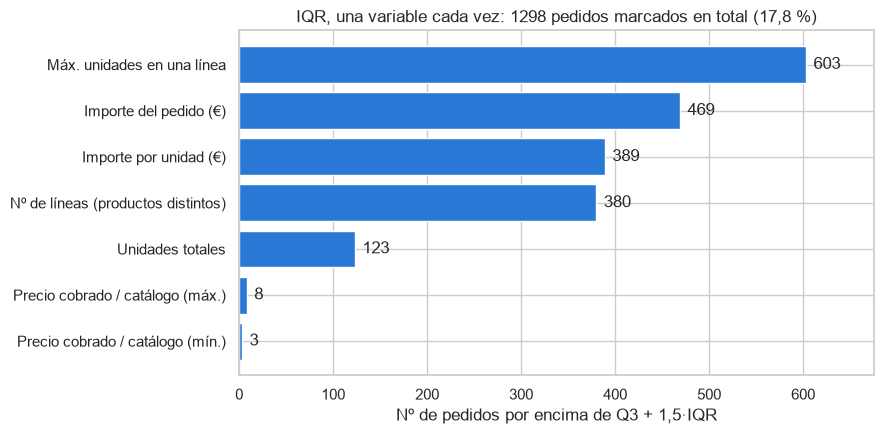

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cuenta = supera.sum().sort_values()
ax.barh([ETIQUETAS[v] for v in cuenta.index], cuenta.values, color=AZUL)
for i, valor in enumerate(cuenta.values):
    ax.text(valor + 8, i, str(valor), va="center")
ax.set_xlabel("Nº de pedidos por encima de Q3 + 1,5·IQR")
ax.set_title(f"IQR, una variable cada vez: {marcado_iqr.sum()} pedidos marcados en total "
             f"({pct(marcado_iqr.mean())})")
ax.set_xlim(0, cuenta.max() * 1.12)
fig.tight_layout()
guardar(fig, "iqr")
plt.show()

**Lectura:** IQR marca **1.298 pedidos (17,8 %)**, 54,1 al mes de media. Tres problemas:

1. **Cuando Q1 y Q3 están juntos, el límite es tan bajo que lo normal sale "outlier".** Q1 = 1 y Q3 = 2
   en líneas y en unidades por línea, así que el límite es 3,5: un pedido con 4 líneas o con 4 unidades
   de un producto ya se marca. Solo por eso salen 380 y 603 pedidos (5,21 % y 8,26 %). El 95,2 % de los
   marcados (1.236) no se sale del percentil 99 en líneas (4) ni en unidades por línea (5) y tiene el
   precio de catálogo.
2. **Solo mira hacia arriba.** En los ratios, Q1 = Q3 = 1 y el límite es 1: cualquier precio por encima
   del catálogo se marca (8 pedidos), pero los 19 pedidos con precio por debajo del catálogo no se marcan
   nunca por el ratio (0). Un descuento del 90 % es tan sospechoso como un sobreprecio ×10.
3. **Mira cada variable por separado.** 836 de los marcados lo están por una sola variable. IQR no ve
   combinaciones: un pedido de 4 líneas con productos caros es más raro que uno de 4 líneas baratas,
   pero para IQR son iguales. Isolation Forest mira todas las variables a la vez.

## 2. Isolation Forest

### La idea: aislar con cortes aleatorios

Un **árbol de aislamiento** coge una variable al azar y hace un corte en un valor al azar entre su
mínimo y su máximo. Repite con cada trozo hasta que cada punto queda solo (o hasta una profundidad
máxima). Un punto **raro** está lejos de los demás, así que un corte al azar lo separa enseguida:
**las anomalías se aíslan con pocos cortes**. Un punto normal está rodeado de otros parecidos y
necesita muchos cortes.

Un solo árbol es muy aleatorio, así que se hacen muchos (un "bosque") y se promedia el número de
cortes de cada punto: **h(x)**.

### La conexión con el ejercicio de clase (puntos A–E)

En clase hicimos árboles a mano con 5 puntos y calculamos la puntuación:

$$s(x, n) = 2^{-\dfrac{E[h(x)]}{c(n)}}, \qquad c(n) = 2\,H(n-1) - \frac{2(n-1)}{n}, \qquad H(i) \approx \ln(i) + 0{,}5772$$

- **c(n)** es el número medio de cortes que necesita un punto cualquiera en un árbol de n puntos.
  Sirve para normalizar: con 5 puntos, 2 cortes es poco; con 256, 2 cortes es poquísimo.
- Si h(x) es mucho menor que c(n), **s se acerca a 1** → anomalía. Si h(x) ≈ c(n), **s ≈ 0,5** → normal.
- **Umbral de clase: s > 0,5 → anomalía.**

Abajo se repite el ejercicio con scikit-learn y se comprueba que su puntuación es la misma fórmula.
Los valores de A–E son un ejemplo con la misma forma que el de clase: cuatro puntos juntos y uno
lejos. Si en clase usaste otros valores, basta con cambiarlos en la celda.

In [8]:
def c(n):
    """Número medio de cortes para aislar un punto en un árbol de n puntos (fórmula de clase)."""
    n = np.asarray(n, dtype=float)
    resultado = np.zeros_like(n)
    resultado[n == 2] = 1.0
    mayor = n > 2
    resultado[mayor] = 2 * (np.log(n[mayor] - 1) + np.euler_gamma) - 2 * (n[mayor] - 1) / n[mayor]
    return resultado


puntos = pd.DataFrame({"x": [1.0, 1.5, 2.0, 2.5, 9.0]}, index=list("ABCDE"))
print(f"c(5) = {num(c(5).item(), 3)} cortes de media para un punto cualquiera")

iso_clase = IsolationForest(n_estimators=300, random_state=SEMILLA).fit(puntos)

# Uno de los 300 árboles, "a mano": qué corte hace en cada nodo
print("\nÁrbol nº 1 del bosque:")
print(export_text(iso_clase.estimators_[0], feature_names=["x"]))

c(5) = 2,327 cortes de media para un punto cualquiera

Árbol nº 1 del bosque:
|--- x <= 4.84
|   |--- x <= 2.27
|   |   |--- x <= 1.16
|   |   |   |--- value: [0.37]
|   |   |--- x >  1.16
|   |   |   |--- value: [0.84]
|   |--- x >  2.27
|   |   |--- value: [0.60]
|--- x >  4.84
|   |--- value: [0.16]



In [9]:
# h(x) de cada punto, calculado a mano a partir de los árboles de scikit-learn:
# nº de cortes hasta su hoja + c(nº de puntos que quedan en la hoja). Ese último término es la
# estimación de los cortes que faltarían: los árboles se paran a una profundidad de log2(n).
X_puntos = puntos.to_numpy()
cortes_totales = np.zeros(len(puntos))
for arbol, columnas in zip(iso_clase.estimators_, iso_clase.estimators_features_):
    X_arbol = X_puntos[:, columnas]
    hojas = arbol.apply(X_arbol)
    cortes = np.asarray(arbol.decision_path(X_arbol).sum(axis=1)).ravel() - 1
    cortes_totales += cortes + c(arbol.tree_.n_node_samples[hojas])
h_media = cortes_totales / len(iso_clase.estimators_)
s_clase = 2 ** (-h_media / c(iso_clase.max_samples_))

tabla_clase = pd.DataFrame({
    "x": puntos["x"],
    "h(x) medio": h_media.round(3),
    "s con la fórmula de clase": s_clase.round(4),
    "-score_samples (sklearn)": (-iso_clase.score_samples(puntos)).round(4),
    "decision_function": iso_clase.decision_function(puntos).round(4),
    "¿anomalía? (s > 0,5)": s_clase > 0.5,
}, index=puntos.index)
assert np.allclose(s_clase, -iso_clase.score_samples(puntos))
print("offset_ con contamination='auto':", iso_clase.offset_)
tabla_clase

offset_ con contamination='auto':

 -0.5


,x,h(x) medio,s con la fórmula de clase,-score_samples (sklearn),decision_function,"¿anomalía? (s > 0,5)"
A,1.0,2.630,0.4569,0.4569,0.0431,False
B,1.5,3.333,0.3705,0.3705,0.1295,False
C,2.0,3.403,0.3629,0.3629,0.1371,False
D,2.5,2.870,0.4253,0.4253,0.0747,False
E,9.0,1.207,0.6981,0.6981,-0.1981,True


**Relación entre scikit-learn y la puntuación de clase** (comprobado arriba con `assert`):

| scikit-learn | Fórmula de clase | Cómo se lee |
|---|---|---|
| `score_samples(X)` | **−s** | Cambia el signo para que "más bajo = más raro" (convenio de sklearn) |
| `decision_function(X)` | −s − `offset_` | Con `contamination="auto"`, `offset_` = −0,5, así que es **0,5 − s**: negativo ⇔ s > 0,5 |
| `predict(X)` | −1 si s > 0,5, 1 si no | Es el **umbral de 0,5 de clase** |

En el resto del notebook se usa **puntuación = −`score_samples`**, es decir, la **s de clase**:
entre 0 y 1, y **cuanto más alta, más sospechoso**.

En el ejemplo, **E (x = 9) se aísla de media en 1,21 cortes**, la mitad que c(5) = 2,33, y su
puntuación es **0,698 > 0,5: anomalía**. A–D necesitan entre 2,63 y 3,40 cortes y puntúan entre 0,363 y
0,457: normales. En el árbol nº 1 se ve: el primer corte (x ≤ 4,84) ya deja a E solo, y los otros
cuatro necesitan dos o tres cortes más. B y C, en el centro del grupo, son los que más cortes
necesitan y los que menos puntúan.

### El pipeline

1. **Transformación logarítmica** (`ColumnTransformer`):
   - `np.log1p` = log(1 + x) en importe, líneas, unidades, máx. unidades por línea e importe por
     unidad. Son variables con cola larga a la derecha (asimetría entre 3 y 25, sección 0). Isolation
     Forest corta en un valor **al azar entre el mínimo y el máximo**: sin log, casi todos los cortes
     caen en la zona vacía de la cola (de 20 a 59 unidades, por ejemplo) y casi ninguno separa 1, 2
     o 5 unidades, que es donde está la mayoría. Con el log, el rango se reparte mejor.
   - `np.log` (sin el +1) en los dos **ratios de precio**. Un ratio es una multiplicación: ×10 y ×0,1
     son "igual de raros". En escala normal, ×0,1 está a 0,9 de 1 y ×10 está a 9: los cortes al azar
     casi nunca caerían entre 0,1 y 1 y los precios bajos serían muy difíciles de aislar. Con el log,
     log(10) = 2,3 y log(0,1) = −2,3: **simétricos**. Se puede usar `log` sin el +1 porque el ratio es
     siempre > 0 (el esquema obliga a precio > 0).
2. **`StandardScaler`**: **no hace falta** en Isolation Forest. Cada corte se elige entre el mínimo y
   el máximo de **una sola variable**, así que cambiar su escala (restar la media y dividir por la
   desviación) mueve los cortes en la misma proporción y los árboles separan exactamente los mismos
   pedidos. Es lo contrario de K-Means o KNN, que usan distancias y sí lo necesitan. Abajo se comprueba
   que la puntuación con y sin él es idéntica. Se deja en el pipeline porque no cambia nada y deja los
   datos listos para el PCA de la sección 5, que sí necesita la misma escala en todas las variables.
3. **`IsolationForest(n_estimators=300, random_state=42)`**: 300 árboles (el valor por defecto es
   100; con más árboles la puntuación media varía menos de una ejecución a otra). Cada árbol usa
   256 pedidos al azar (`max_samples="auto"`), lo habitual en Isolation Forest: con pocos puntos, los
   normales no "tapan" a las anomalías.

Se usan funciones de numpy (`np.log1p`, `np.log`) y no funciones propias del notebook para que el
`.joblib` se pueda cargar desde otro programa (lo mismo que en la S7).

In [10]:
VARIABLES_LOG1P = ["importe_total", "n_lineas", "unidades_totales", "max_cantidad_linea", "importe_por_unidad"]
VARIABLES_RATIO = ["ratio_precio_max", "ratio_precio_min"]
assert sorted(VARIABLES_LOG1P + VARIABLES_RATIO) == sorted(VARIABLES)


def crear_pipeline(log1p, ratios, semilla=SEMILLA, escalar=True):
    """Transformación log -> (StandardScaler) -> IsolationForest. Se reutiliza en la estabilidad y la ablación."""
    transformaciones = [("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), log1p)]
    if ratios:
        transformaciones.append(("log", FunctionTransformer(np.log, feature_names_out="one-to-one"), ratios))
    pasos = [("log", ColumnTransformer(transformaciones))]
    if escalar:
        pasos.append(("escalar", StandardScaler()))
    pasos.append(("iforest", IsolationForest(n_estimators=300, random_state=semilla)))
    return Pipeline(pasos)


def puntuar(pipeline, datos):
    """Puntuación de clase s = -score_samples: entre 0 y 1, más alta = más sospechoso."""
    return -pipeline.score_samples(datos)


pipeline = crear_pipeline(VARIABLES_LOG1P, VARIABLES_RATIO).fit(pedidos[VARIABLES])
pedidos["puntuacion"] = puntuar(pipeline, pedidos[VARIABLES])

# ¿Hace falta el StandardScaler? Mismo modelo sin él:
sin_escalar = crear_pipeline(VARIABLES_LOG1P, VARIABLES_RATIO, escalar=False).fit(pedidos[VARIABLES])
diferencia = np.abs(puntuar(sin_escalar, pedidos[VARIABLES]) - pedidos["puntuacion"]).max()
print(f"Diferencia máxima de puntuación con y sin StandardScaler: {diferencia:.2e}")

print(f"\nPuntuación: mínimo {num(pedidos['puntuacion'].min(), 3)}, mediana {num(pedidos['puntuacion'].median(), 3)}, "
      f"máximo {num(pedidos['puntuacion'].max(), 3)}")
pedidos["puntuacion"].describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(3).to_frame().T

Diferencia máxima de puntuación con y sin StandardScaler: 0.00e+00

Puntuación: mínimo 0,401, mediana 0,448, máximo 0,752


,count,mean,std,min,50%,75%,90%,99%,max
puntuacion,7297.0,0.464,0.057,0.401,0.448,0.496,0.551,0.641,0.752


**Lectura:** la puntuación va de 0,401 a 0,752, con mediana 0,448: la mayoría de los pedidos está por
debajo de 0,5, es decir, se aísla con más cortes que la media (normal). Solo el 1 % pasa de 0,641. La
diferencia máxima con y sin `StandardScaler` es 0: confirma que el escalado no afecta a Isolation
Forest.

## 3. Umbral con criterio de negocio

El modelo ordena los pedidos de más a menos sospechoso, pero **no dice dónde cortar**. Hay dos
opciones:

- **`contamination="auto"`**: el umbral de clase, s > 0,5.
- **Capacidad de revisión**: el equipo puede revisar a mano **50 pedidos al mes**. Si llegan de media
  N pedidos al mes, se puede revisar el 50 / N de los pedidos: el umbral es la puntuación que deja
  por encima ese porcentaje.

No se usa el 1 % que sabemos que plantó el generador: en una empresa real ese número no existe.

In [11]:
CAPACIDAD_MENSUAL = 50
pedidos["mes"] = pedidos["fecha_pedido"].dt.to_period("M")
pedidos_mes = pedidos.groupby("mes").size()
pct_capacidad = CAPACIDAD_MENSUAL / pedidos_mes.mean()
umbral_capacidad = float(np.quantile(pedidos["puntuacion"], 1 - pct_capacidad))
UMBRAL_AUTO = 0.5

print(f"Pedidos al mes: media {num(pedidos_mes.mean(), 1)}, mínimo {pedidos_mes.min()} ({pedidos_mes.idxmin()}), "
      f"máximo {pedidos_mes.max()} ({pedidos_mes.idxmax()})")
print(f"Capacidad: {CAPACIDAD_MENSUAL} / {num(pedidos_mes.mean(), 1)} = {pct(pct_capacidad, 2)} de los pedidos")

comparacion = pd.DataFrame({
    "umbral (puntuación s)": [umbral_capacidad, UMBRAL_AUTO],
    "pedidos marcados": [(pedidos["puntuacion"] >= umbral_capacidad).sum(), (pedidos["puntuacion"] > UMBRAL_AUTO).sum()],
}, index=["capacidad (50 al mes)", "contamination='auto' (s > 0,5)"])
comparacion["% de pedidos"] = (100 * comparacion["pedidos marcados"] / len(pedidos)).round(2)
comparacion["marcados al mes (media)"] = (comparacion["pedidos marcados"] / len(pedidos_mes)).round(1)
comparacion["meses por encima de 50"] = [
    (pedidos[pedidos["puntuacion"] >= umbral_capacidad].groupby("mes").size() > CAPACIDAD_MENSUAL).sum(),
    (pedidos[pedidos["puntuacion"] > UMBRAL_AUTO].groupby("mes").size() > CAPACIDAD_MENSUAL).sum(),
]
assert (iso_auto := (pipeline.predict(pedidos[VARIABLES]) == -1).sum()) == comparacion.iloc[1, 1]
comparacion.round(3)

Pedidos al mes: media 304,0, mínimo 190 (2026-08), máximo 454 (2024-11)
Capacidad: 50 / 304,0 = 16,45 % de los pedidos


,umbral (puntuación s),pedidos marcados,% de pedidos,marcados al mes (media),meses por encima de 50
capacidad (50 al mes),0.529,1200,16.45,50.0,11
"contamination='auto' (s > 0,5)",0.500,1710,23.43,71.2,22


**Decisión:** se elige el **umbral de capacidad: s ≥ 0,529, el 16,45 % de los pedidos (1.200 en
total, 50 al mes de media)**.

- `contamination="auto"` marca 1.710 pedidos (23,43 %), 71,2 al mes: **los 24 meses superan la
  capacidad**. Un umbral que da más alertas de las que se pueden revisar no sirve: las que sobran se
  quedan sin mirar, y sin ningún criterio.
- El 0,5 viene de la teoría (h(x) = c(n)), no del negocio. El de capacidad responde a la pregunta real:
  "¿qué pedidos miramos con el tiempo que tenemos?". Y como el modelo ordena por puntuación, se miran
  primero los más sospechosos.
- El criterio se puede mover si cambia el equipo: con 25 revisiones al mes, el umbral subiría.

In [12]:
UMBRAL = umbral_capacidad
pedidos["marcado"] = pedidos["puntuacion"] >= UMBRAL
marcados_mes = pedidos.groupby("mes")["marcado"].sum()
print(f"Umbral elegido: s ≥ {num(UMBRAL, 4)} → {pedidos['marcado'].sum()} pedidos marcados ({pct(pedidos['marcado'].mean(), 2)})")
print(f"Marcados al mes: media {num(marcados_mes.mean(), 1)}, mínimo {marcados_mes.min()}, máximo {marcados_mes.max()} ({marcados_mes.idxmax()})")
print(f"Meses por encima de la capacidad: {(marcados_mes > CAPACIDAD_MENSUAL).sum()} de {len(marcados_mes)}")
print(f"Coinciden con IQR: {(pedidos['marcado'] & marcado_iqr).sum()} de {pedidos['marcado'].sum()}")

Umbral elegido: s ≥ 0,5294 → 1200 pedidos marcados (16,45 %)
Marcados al mes: media 50,0, mínimo 26, máximo 74 (2024-11)
Meses por encima de la capacidad: 11 de 24
Coinciden con IQR: 834 de 1200


**Lectura:** con un umbral fijo, el número de marcados sigue al volumen de pedidos: de 26 a 74
al mes, y **11 de los 24 meses pasan de 50** (el máximo, 74, en 2024-11). El porcentaje se calcula con la
media de pedidos al mes, así que en los meses de más ventas (como 2024-11) hay más alertas. En
esos meses el equipo revisa por orden de `ranking` hasta completar los 50; en los tranquilos le sobra
tiempo. 834 de los 1.200 marcados también los marca IQR.

## 4. Explicar cada alerta

Isolation Forest da una puntuación, pero no dice **por qué**. Para que alguien de negocio entienda
cada alerta, se busca la variable más extrema del pedido:

1. Se trabaja con las variables ya transformadas (log), como las ve el modelo.
2. Para cada variable, **desviación robusta** = (valor − mediana) / escala, con
   escala = 1,4826 · MAD (MAD = mediana de |valor − mediana|). Es como una puntuación z, pero con la
   mediana en lugar de la media: los pedidos raros no deforman la referencia. El 1,4826 hace que, con
   datos normales, la escala coincida con la desviación típica.
3. Si la MAD es 0 (más de la mitad de los pedidos tiene el mismo valor, como 1 línea o precio de
   catálogo), se usa 1,2533 · la desviación media absoluta respecto a la mediana: es la versión
   habitual de la "puntuación z modificada" para ese caso.
4. **Motivo principal** = la variable con la mayor desviación robusta (en valor absoluto), escrita en
   palabras.

In [13]:
transformado = pd.DataFrame(pipeline.named_steps["log"].transform(pedidos[VARIABLES]),
                            columns=pipeline.named_steps["log"].get_feature_names_out(),
                            index=pedidos.index)
transformado.columns = [col.split("__")[1] for col in transformado.columns]
transformado = transformado[VARIABLES]

mediana_t = transformado.median()
mad = (transformado - mediana_t).abs().median()
desv_media = (transformado - mediana_t).abs().mean()
escala_t = (1.4826 * mad).where(mad > 0, 1.2533 * desv_media)
desviacion = (transformado - mediana_t) / escala_t

referencia_motivo = pd.DataFrame({"mediana (log)": mediana_t, "MAD": mad, "escala usada": escala_t,
                                  "mediana original": pedidos[VARIABLES].median()})
referencia_motivo.round(4)

,mediana (log),MAD,escala usada,mediana original
importe_total,4.4415,0.6683,0.9908,83.9000
n_lineas,0.6931,0.0000,0.2771,1.0000
unidades_totales,1.0986,0.4055,0.6011,2.0000
max_cantidad_linea,1.0986,0.4055,0.6011,2.0000
ratio_precio_max,0.0000,0.0000,0.0056,1.0000
ratio_precio_min,0.0000,0.0000,0.0072,1.0000
importe_por_unidad,3.7056,0.3923,0.5816,39.6733


In [14]:
MEDIANAS = pedidos[VARIABLES].median()


def describir_motivo(variable, valor, sentido):
    """Texto para negocio: qué variable es rara, en qué sentido y cuánto vale frente a lo normal."""
    if variable.startswith("ratio"):
        lado = "por encima" if valor > 1 else "por debajo"
        return f"Precio {lado} del catálogo (×{num(valor, 2)})"
    alto_bajo = "alto" if sentido > 0 else "bajo"
    textos = {
        "importe_total": f"Importe {alto_bajo}: {euros(valor)} (mediana {euros(MEDIANAS[variable])})",
        "n_lineas": f"{'Muchas' if sentido > 0 else 'Pocas'} líneas: {valor:.0f} (mediana {MEDIANAS[variable]:.0f})",
        "unidades_totales": f"{'Muchas' if sentido > 0 else 'Pocas'} unidades: {valor:.0f} (mediana {MEDIANAS[variable]:.0f})",
        "max_cantidad_linea": f"{valor:.0f} unidades en una línea (mediana {MEDIANAS[variable]:.0f})",
        "importe_por_unidad": f"Importe por unidad {alto_bajo}: {euros(valor)} (mediana {euros(MEDIANAS[variable])})",
    }
    return textos[variable]


variable_motivo = desviacion.abs().idxmax(axis=1)
pedidos["variable_motivo"] = variable_motivo
pedidos["desviacion_motivo"] = [desviacion.at[i, v] for i, v in variable_motivo.items()]
pedidos["motivo_principal"] = [
    describir_motivo(v, pedidos.at[i, v], pedidos.at[i, "desviacion_motivo"]) for i, v in variable_motivo.items()
]

# Ranking: 1 = el más sospechoso. Con empates, gana el id_pedido más bajo (orden estable)
pedidos = pedidos.sort_values(["puntuacion", "id_pedido"], ascending=[False, True], kind="stable")
pedidos["ranking"] = np.arange(1, len(pedidos) + 1)
pedidos = pedidos.sort_values("id_pedido").reset_index(drop=True)
desviacion = desviacion.loc[pedidos.index]

top15 = pedidos.nsmallest(15, "ranking")
top15[["ranking", "id_pedido", "estado", "puntuacion"] + VARIABLES + ["motivo_principal"]].round(
    {"puntuacion": 3, "importe_total": 2, "ratio_precio_max": 2, "ratio_precio_min": 2, "importe_por_unidad": 2})

,ranking,id_pedido,estado,puntuacion,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad,motivo_principal
322,1,348,completado,0.752,11730.42,1,54,54,1.0,1.0,217.23,Importe alto: 11.730 € (mediana 84 €)
5994,2,6477,completado,0.748,10389.60,1,48,48,1.0,1.0,216.45,Importe alto: 10.390 € (mediana 84 €)
2599,3,2791,completado,0.733,755.79,1,59,59,1.0,1.0,12.81,Muchas unidades: 59 (mediana 2)
4398,4,4745,completado,0.732,530.12,1,58,58,1.0,1.0,9.14,Muchas unidades: 58 (mediana 2)
3298,5,3547,completado,0.731,3435.50,1,50,50,1.0,1.0,68.71,Muchas unidades: 50 (mediana 2)
7085,6,7664,cancelado,0.729,921.62,1,58,58,1.0,1.0,15.89,Muchas unidades: 58 (mediana 2)
2035,7,2183,devuelto,0.728,3019.71,1,51,51,1.0,1.0,59.21,Muchas unidades: 51 (mediana 2)
5450,8,5886,completado,0.727,2897.88,1,57,57,1.0,1.0,50.84,Muchas unidades: 57 (mediana 2)
3777,9,4071,completado,0.725,2288.88,1,51,51,1.0,1.0,44.88,Muchas unidades: 51 (mediana 2)
7223,10,7813,completado,0.723,3147.04,3,46,43,1.0,1.0,68.41,Muchas unidades: 46 (mediana 2)


In [15]:
# Motivo principal de todos los pedidos marcados
print(pedidos.loc[pedidos["marcado"], "variable_motivo"].map(ETIQUETAS).value_counts().to_string())

variable_motivo
Importe por unidad (€)                690
Nº de líneas (productos distintos)    361
Unidades totales                       73
Importe del pedido (€)                 55
Precio cobrado / catálogo (máx.)       13
Precio cobrado / catálogo (mín.)        8


**Lectura:** los 15 pedidos más sospechosos son pedidos de 46 a 59 unidades (14 de 15), con
importes de hasta 11.730,42 €, y uno de 10 líneas (puesto 12). En los dos primeros el motivo es el
importe (11.730 € y 10.390 €), que se sale un poco más que las unidades en desviaciones robustas. Entre
los 1.200 marcados, el motivo más frecuente es el **importe por unidad alto (690)**: pedidos de productos
caros, que tiene sentido revisar por dinero, pero que no son raros por sí mismos. Después vienen muchas
líneas (361), muchas unidades (73), importe alto (55) y precio distinto al de catálogo (13 + 8 = 21).

Así, alguien de negocio no ve solo "puntuación 0,73": ve "**59 unidades en un pedido cuando lo normal
son 2**".

## 5. Gráficos (sin la verdad)

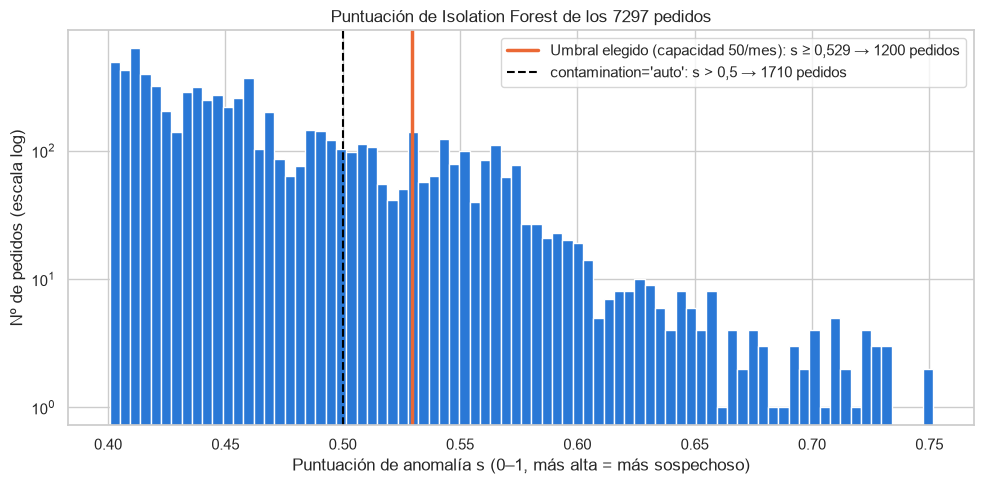

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pedidos["puntuacion"], bins=80, color=AZUL, edgecolor="white")
ax.axvline(UMBRAL, color=NARANJA, linewidth=2.5,
           label=f"Umbral elegido (capacidad 50/mes): s ≥ {num(UMBRAL, 3)} → {pedidos['marcado'].sum()} pedidos")
ax.axvline(UMBRAL_AUTO, color="black", linestyle="--", linewidth=1.5,
           label=f"contamination='auto': s > 0,5 → {comparacion.iloc[1, 1]} pedidos")
ax.set_yscale("log")
ax.set_xlabel("Puntuación de anomalía s (0–1, más alta = más sospechoso)")
ax.set_ylabel("Nº de pedidos (escala log)")
ax.set_title(f"Puntuación de Isolation Forest de los {len(pedidos)} pedidos")
ax.legend()
fig.tight_layout()
guardar(fig, "puntuaciones")
plt.show()

**Lectura:** la mayoría de los pedidos puntúa entre 0,40 y 0,50 y la cola baja de forma gradual:
**no hay un hueco** que separe a los normales de los raros. Por eso el umbral no puede salir "solo" de los
datos y hace falta un criterio de negocio. Solo el 1 % de los pedidos pasa de 0,641; ahí están los
pedidos más extremos, que son los primeros del ranking.

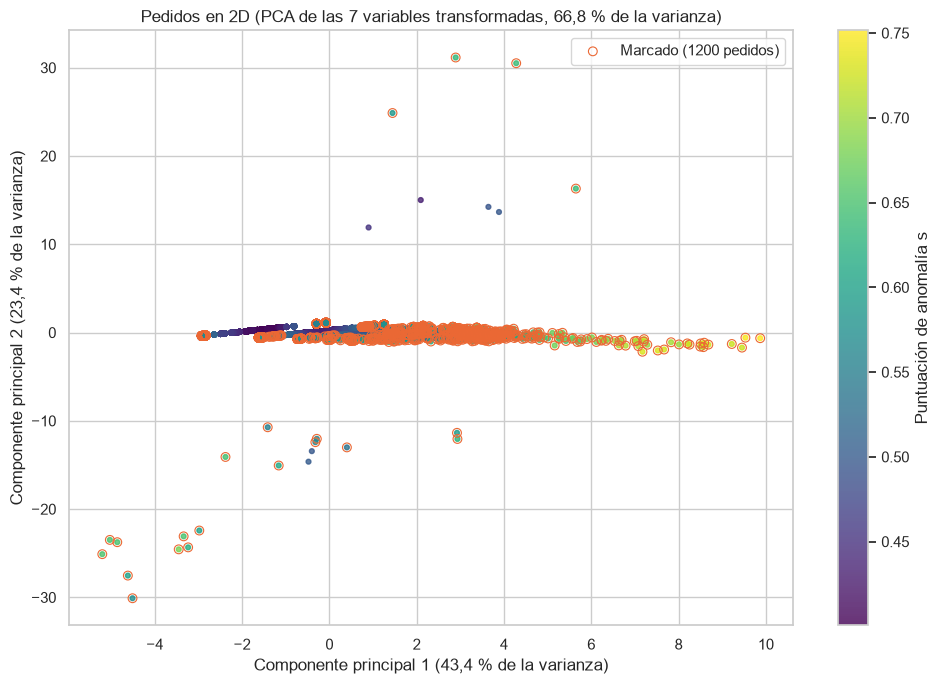

,CP1,CP2
importe_total,0.53,0.08
n_lineas,0.42,-0.09
unidades_totales,0.54,-0.14
max_cantidad_linea,0.44,-0.12
ratio_precio_max,0.24,0.26
ratio_precio_min,0.06,0.66
importe_por_unidad,0.04,0.67


In [17]:
X_escalado = pipeline[:-1].transform(pedidos[VARIABLES])
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_escalado)
coords = pca.transform(X_escalado)
varianza = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10, 7))
orden = np.argsort(pedidos["puntuacion"].to_numpy())  # los más sospechosos se dibujan encima
puntos_pca = ax.scatter(coords[orden, 0], coords[orden, 1], c=pedidos["puntuacion"].to_numpy()[orden],
                        cmap="viridis", s=12, alpha=0.8)
marc = pedidos["marcado"].to_numpy()
ax.scatter(coords[marc, 0], coords[marc, 1], facecolors="none", edgecolors=NARANJA, s=40, linewidths=0.8,
           label=f"Marcado ({marc.sum()} pedidos)")
fig.colorbar(puntos_pca, ax=ax, label="Puntuación de anomalía s")
ax.set_xlabel(f"Componente principal 1 ({pct(varianza[0])} de la varianza)")
ax.set_ylabel(f"Componente principal 2 ({pct(varianza[1])} de la varianza)")
ax.set_title(f"Pedidos en 2D (PCA de las 7 variables transformadas, {pct(varianza.sum())} de la varianza)")
ax.legend(loc="upper right")
fig.tight_layout()
guardar(fig, "pca")
plt.show()

cargas = pd.DataFrame(pca.components_.T, index=VARIABLES, columns=["CP1", "CP2"]).round(2)
cargas

**Lectura:** el PCA resume las 7 variables en 2 con el 66,8 % de la varianza. La **componente 1
(43,4 %)** es el **tamaño del pedido**: pesan importe, unidades, líneas y máx. unidades por línea
(cargas de 0,42 a 0,54). La **componente 2 (23,4 %)** es el **precio**: pesan el ratio mínimo (0,66) y el
importe por unidad (0,67). Los pedidos más sospechosos (amarillo) están a la derecha: los más grandes. Los
puntos sueltos muy por encima o por debajo de la nube tienen valores extremos en la componente 2, es
decir, precios lejos del catálogo. **Varios de ellos tienen una puntuación baja (morado o azul) y no
están marcados**, aunque en 2D se ven claramente aislados.

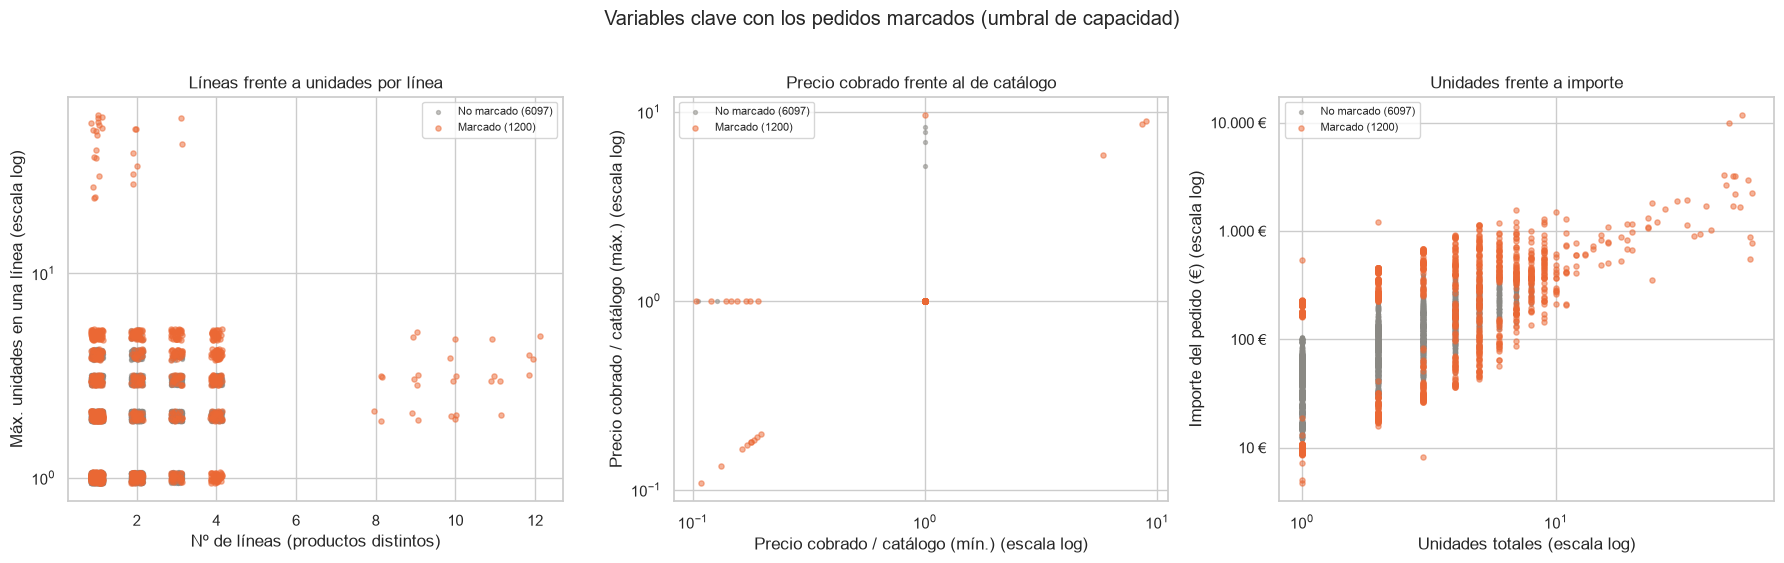

Pedidos con 8 o más líneas: 27, marcados: 27
Pedidos con 20 o más unidades en una línea: 25, marcados: 25
Pedidos con precio por encima del catálogo: 8, marcados: 4
Pedidos con precio por debajo del catálogo: 19, marcados: 17


In [18]:
rng = np.random.default_rng(SEMILLA)  # pequeño "jitter" para que no se tapen los valores enteros repetidos


def jitter(serie, ancho=0.15):
    return serie + rng.uniform(-ancho, ancho, size=len(serie))


normales = pedidos[~pedidos["marcado"]]
sospechosos = pedidos[pedidos["marcado"]]
fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
paneles = [
    ("n_lineas", "max_cantidad_linea", False, True),
    ("ratio_precio_min", "ratio_precio_max", True, True),
    ("unidades_totales", "importe_total", True, True),
]
for ax, (vx, vy, logx, logy) in zip(ejes, paneles):
    for datos, color, nombre, tam in [(normales, GRIS, f"No marcado ({len(normales)})", 8),
                                      (sospechosos, NARANJA, f"Marcado ({len(sospechosos)})", 14)]:
        x = datos[vx] if logx else jitter(datos[vx])
        y = datos[vy] if vx.startswith("ratio") else datos[vy] * np.exp(rng.uniform(-0.06, 0.06, size=len(datos)))
        ax.scatter(x, y, s=tam, color=color, alpha=0.5, label=nombre)
    if logx:
        ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(ETIQUETAS[vx] + (" (escala log)" if logx else ""))
    ax.set_ylabel(ETIQUETAS[vy] + (" (escala log)" if logy else ""))
    ax.legend(fontsize=8)
ejes[0].set_title("Líneas frente a unidades por línea")
ejes[1].set_title("Precio cobrado frente al de catálogo")
ejes[2].set_title("Unidades frente a importe")
ejes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _p: euros(v)))
fig.suptitle("Variables clave con los pedidos marcados (umbral de capacidad)", y=1.02)
fig.tight_layout()
guardar(fig, "dispersion")
plt.show()

print(f"Pedidos con 8 o más líneas: {(pedidos['n_lineas'] >= 8).sum()}, marcados: "
      f"{(pedidos['marcado'] & (pedidos['n_lineas'] >= 8)).sum()}")
print(f"Pedidos con 20 o más unidades en una línea: {(pedidos['max_cantidad_linea'] >= 20).sum()}, marcados: "
      f"{(pedidos['marcado'] & (pedidos['max_cantidad_linea'] >= 20)).sum()}")
por_encima = pedidos["ratio_precio_max"] > 1.001
por_debajo = pedidos["ratio_precio_min"] < 0.999
print(f"Pedidos con precio por encima del catálogo: {por_encima.sum()}, marcados: {(pedidos['marcado'] & por_encima).sum()}")
print(f"Pedidos con precio por debajo del catálogo: {por_debajo.sum()}, marcados: {(pedidos['marcado'] & por_debajo).sum()}")

**Lectura:** los 27 pedidos con 8 o más líneas y los 25 con 20 o más unidades en una línea están
todos marcados (izquierda). En precios (centro), se marcan 17 de los 19 pedidos con precio por debajo
del catálogo, pero **solo 4 de los 8 con precio por encima**: son los puntos grises de arriba. A la derecha se ve que muchos pedidos marcados tienen 1–4 unidades: son los de productos caros
(importe por unidad alto) o muy baratos. Son los que completan la capacidad de 50 al mes.

## 6. Estabilidad

Isolation Forest es aleatorio (qué pedidos usa cada árbol, qué variable y qué valor corta). Si con
otra semilla marcara pedidos muy distintos, las alertas dependerían de la suerte. Se repite el modelo
con 5 semillas distintas, con el mismo criterio de umbral (el mismo % de pedidos), y se mide:

- **Jaccard** = |A ∩ B| / |A ∪ B| entre los pedidos marcados: 1 = los mismos, 0 = ninguno en común.
- El solape del **top 50** (los que se revisarían primero).
- La **correlación de Spearman** entre las puntuaciones (si ordenan igual los pedidos).

In [19]:
SEMILLAS_ESTABILIDAD = [1, 2, 3, 4, 5]
n_marcados = int(pedidos["marcado"].sum())


def conjunto_marcados(puntuacion, n):
    """Los n pedidos con más puntuación (con empates, el id más bajo, como en el ranking)."""
    orden = pd.DataFrame({"s": puntuacion, "id": pedidos["id_pedido"]}).sort_values(
        ["s", "id"], ascending=[False, True], kind="stable")
    return set(orden["id"].head(n))


def jaccard(a, b):
    return len(a & b) / len(a | b)


puntuaciones = {SEMILLA: pedidos["puntuacion"].to_numpy()}
for semilla in SEMILLAS_ESTABILIDAD:
    modelo = crear_pipeline(VARIABLES_LOG1P, VARIABLES_RATIO, semilla=semilla).fit(pedidos[VARIABLES])
    puntuaciones[semilla] = puntuar(modelo, pedidos[VARIABLES])

base_marcados = conjunto_marcados(puntuaciones[SEMILLA], n_marcados)
base_top50 = conjunto_marcados(puntuaciones[SEMILLA], 50)
filas = []
for semilla in SEMILLAS_ESTABILIDAD:
    marcados_s = conjunto_marcados(puntuaciones[semilla], n_marcados)
    top50_s = conjunto_marcados(puntuaciones[semilla], 50)
    filas.append({
        "semilla": semilla,
        "Jaccard marcados (vs 42)": jaccard(marcados_s, base_marcados),
        "% de los marcados en común": 100 * len(marcados_s & base_marcados) / n_marcados,
        "top 50 en común": len(top50_s & base_top50),
        "Spearman puntuaciones": spearmanr(puntuaciones[semilla], puntuaciones[SEMILLA]).statistic,
    })
estabilidad = pd.DataFrame(filas).set_index("semilla")

# Pedidos marcados con las 6 semillas a la vez
todas = set.intersection(*[conjunto_marcados(p, n_marcados) for p in puntuaciones.values()])
alguna = set.union(*[conjunto_marcados(p, n_marcados) for p in puntuaciones.values()])
print(f"Marcados por cada modelo: {n_marcados}")
print(f"Marcados con las 6 semillas: {len(todas)} · con alguna: {len(alguna)}")
print(f"Jaccard medio con la semilla 42: {num(estabilidad['Jaccard marcados (vs 42)'].mean(), 3)}")
estabilidad.round(3)

Marcados por cada modelo: 1200
Marcados con las 6 semillas: 1076 · con alguna: 1314
Jaccard medio con la semilla 42: 0,895


,Jaccard marcados (vs 42),% de los marcados en común,top 50 en común,Spearman puntuaciones
semilla,,,,
1,0.905,95.000,46,0.992
2,0.860,92.500,47,0.988
3,0.908,95.167,47,0.979
4,0.920,95.833,47,0.988
5,0.884,93.833,47,0.989


**Lectura:** el modelo es **estable**. Con otras semillas, entre el 92,5 % y el 95,8 % de los pedidos
marcados coinciden con los de la semilla 42 (Jaccard medio 0,895), del top 50 coinciden 46 o 47, y la
correlación de Spearman entre puntuaciones está entre 0,979 y 0,992. 1.076 pedidos se marcan con las 6
semillas y 1.314 con alguna: unos 238 pedidos están en el borde del umbral y entran o salen según el
azar. Para el negocio: **las alertas de arriba del ranking son fiables**; las que están justo en el
umbral tienen puntuaciones casi iguales a las de los pedidos que se quedan fuera, y da casi igual
revisar unas u otras.

## 6b. Guardar el modelo y el CSV

Se guardan antes de la evaluación: el modelo y el umbral no dependen de la verdad.

In [20]:
# "datos_hasta" es el último día con pedidos (no la fecha de hoy): con los mismos datos, el archivo es
# idéntico entre ejecuciones. "referencia_motivo" permite explicar las alertas de pedidos nuevos.
paquete = {
    "pipeline": pipeline,
    "variables": VARIABLES,
    "variables_log1p": VARIABLES_LOG1P,
    "variables_log": VARIABLES_RATIO,
    "puntuacion": "s = -pipeline.score_samples(X): entre 0 y 1, más alta = más sospechoso",
    "umbral": UMBRAL,
    "criterio_umbral": f"capacidad de revisión de {CAPACIDAD_MENSUAL} pedidos al mes "
                       f"({pct(pct_capacidad, 2)} de los pedidos)",
    "pct_marcado": float(pct_capacidad),
    "referencia_motivo": {"mediana": mediana_t.round(10).to_dict(), "escala": escala_t.round(10).to_dict()},
    "datos_hasta": str(pedidos["fecha_pedido"].max().date()),
}
ruta_modelo = CARPETA_MODELOS / "anomalias_iforest.joblib"
joblib.dump(paquete, ruta_modelo)
print("Modelo guardado en", ruta_modelo.relative_to(RAIZ))

# Comprobación: se carga, da las mismas puntuaciones y puntúa pedidos "nuevos"
cargado = joblib.load(ruta_modelo)
s_cargado = -cargado["pipeline"].score_samples(pedidos[cargado["variables"]])
assert np.allclose(s_cargado, pedidos["puntuacion"])
assert ((s_cargado >= cargado["umbral"]) == pedidos["marcado"]).all()
ejemplo = pd.DataFrame({
    "importe_total": [60.0, 2400.0, 6.0], "n_lineas": [1, 1, 1], "unidades_totales": [2, 40, 1],
    "max_cantidad_linea": [2, 40, 1], "ratio_precio_max": [1.0, 1.0, 0.12], "ratio_precio_min": [1.0, 1.0, 0.12],
    "importe_por_unidad": [30.0, 60.0, 6.0],
}, index=["normal", "40 unidades", "precio ×0,12"])
s_ejemplo = -cargado["pipeline"].score_samples(ejemplo[cargado["variables"]])
for nombre, s in zip(ejemplo.index, s_ejemplo):
    print(f"Pedido {nombre:<12} → s = {num(s, 3)} → {'MARCADO' if s >= cargado['umbral'] else 'no marcado'}")
print("datos_hasta =", cargado["datos_hasta"])

Modelo guardado en models\anomalias_iforest.joblib
Pedido normal       → s = 0,419 → no marcado
Pedido 40 unidades  → s = 0,718 → MARCADO
Pedido precio ×0,12 → s = 0,659 → MARCADO
datos_hasta = 2026-10-31


In [21]:
# Para el Power BI de la S10. motivo_principal solo se rellena en los pedidos marcados: en un pedido
# normal, la variable "más extrema" no es un motivo de nada y confundiría al leer el informe.
sospechosos_csv = pedidos[["id_pedido", "puntuacion", "ranking", "marcado", "motivo_principal"]].copy()
sospechosos_csv["puntuacion"] = sospechosos_csv["puntuacion"].round(6)
sospechosos_csv["marcado"] = sospechosos_csv["marcado"].astype(int)
sospechosos_csv.loc[sospechosos_csv["marcado"] == 0, "motivo_principal"] = ""
ruta_csv = RAIZ / "data" / "processed" / "pedidos_sospechosos.csv"
sospechosos_csv.to_csv(ruta_csv, index=False, encoding="utf-8")
print(f"Guardado {ruta_csv.relative_to(RAIZ)}: {len(sospechosos_csv)} pedidos, {sospechosos_csv['marcado'].sum()} marcados")
sospechosos_csv.sort_values("ranking").head()

Guardado data\processed\pedidos_sospechosos.csv: 7297 pedidos, 1200 marcados

,id_pedido,puntuacion,ranking,marcado,motivo_principal
322,348,0.751503,1,1,Importe alto: 11.730 € (mediana 84 €)
5994,6477,0.747525,2,1,Importe alto: 10.390 € (mediana 84 €)
2599,2791,0.733294,3,1,Muchas unidades: 59 (mediana 2)
4398,4745,0.731671,4,1,Muchas unidades: 58 (mediana 2)
3298,3547,0.731425,5,1,Muchas unidades: 50 (mediana 2)


---

## 7. EVALUACIÓN con la verdad

> **A partir de aquí se usa `_verdad_anomalias.csv`.** Nada de lo anterior (variables, transformación,
> hiperparámetros, umbral) se ha decidido con ella. En una empresa real esta sección no existe.

Métricas (anomalía = clase positiva):

- **Precision** = de los pedidos marcados, cuántos son anomalías de verdad.
- **Recall** = de las anomalías de verdad, cuántas se marcan.
- **F1** = media armónica de las dos: solo es alta si las dos lo son.
- **ROC-AUC** = probabilidad de que una anomalía al azar tenga más puntuación que un pedido normal al
  azar (0,5 = azar, 1 = perfecto). No depende del umbral.
- **Average precision (PR-AUC)** = área bajo la curva precision–recall. Con clases muy desequilibradas
  es más exigente que la ROC-AUC: el azar da la proporción de anomalías, no 0,5.

In [22]:
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,  # noqa: E402
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score)

verdad = pd.read_csv(RAIZ / "data" / "raw" / "_verdad_anomalias.csv")
assert verdad["id_pedido"].isin(pedidos["id_pedido"]).all()
evaluacion = pedidos.merge(verdad, on="id_pedido", how="left")
evaluacion["es_anomalia"] = evaluacion["tipo_anomalia"].notna()
# El generador solo dice "precio_anomalo": se separa en alto o bajo con el ratio del propio pedido
precio = evaluacion["tipo_anomalia"] == "precio_anomalo"
evaluacion.loc[precio, "tipo_anomalia"] = np.where(evaluacion.loc[precio, "ratio_precio_max"] > 1.001,
                                                   "precio_alto", "precio_bajo")
evaluacion["marcado_iqr"] = marcado_iqr.to_numpy()
y = evaluacion["es_anomalia"]

prevalencia = y.mean()
print(f"Anomalías reales: {y.sum()} de {len(y)} ({pct(prevalencia, 2)})")
print(evaluacion.loc[y, "tipo_anomalia"].value_counts().to_string())
print(f"\nAccuracy de un 'modelo' que no marca NADA: {pct(1 - prevalencia, 2)} (y no encuentra ni una anomalía)")

Anomalías reales: 79 de 7297 (1,08 %)
tipo_anomalia
muchas_lineas      27
cantidad_enorme    25
precio_bajo        19
precio_alto         8

Accuracy de un 'modelo' que no marca NADA: 98,92 % (y no encuentra ni una anomalía)


In [23]:
def metricas(nombre, marcado):
    return {
        "método": nombre,
        "marcados": int(marcado.sum()),
        "anomalías encontradas": int((marcado & y).sum()),
        "precision": precision_score(y, marcado),
        "recall": recall_score(y, marcado),
        "F1": f1_score(y, marcado),
        "accuracy": (marcado == y).mean(),
    }


tabla_metricas = pd.DataFrame([
    metricas("IQR (una variable cada vez)", evaluacion["marcado_iqr"]),
    metricas("Isolation Forest, umbral de capacidad", evaluacion["marcado"]),
    metricas("Isolation Forest, contamination='auto'", evaluacion["puntuacion"] > UMBRAL_AUTO),
]).set_index("método")
roc_auc = roc_auc_score(y, evaluacion["puntuacion"])
ap = average_precision_score(y, evaluacion["puntuacion"])
print(f"Precision máxima posible marcando {int(evaluacion['marcado'].sum())} pedidos: "
      f"{y.sum()} / {int(evaluacion['marcado'].sum())} = {pct(y.sum() / evaluacion['marcado'].sum())}")
print(f"Isolation Forest con la puntuación continua: ROC-AUC = {num(roc_auc, 3)} · "
      f"average precision (PR-AUC) = {num(ap, 3)} (azar = {num(prevalencia, 3)})")
tabla_metricas.round(3)

Precision máxima posible marcando 1200 pedidos: 79 / 1200 = 6,6 %
Isolation Forest con la puntuación continua: ROC-AUC = 0,968 · average precision (PR-AUC) = 0,762 (azar = 0,011)


,marcados,anomalías encontradas,precision,recall,F1,accuracy
método,,,,,,
IQR (una variable cada vez),1298,62,0.048,0.785,0.090,0.828
"Isolation Forest, umbral de capacidad",1200,73,0.061,0.924,0.114,0.845
"Isolation Forest, contamination='auto'",1710,74,0.043,0.937,0.083,0.775


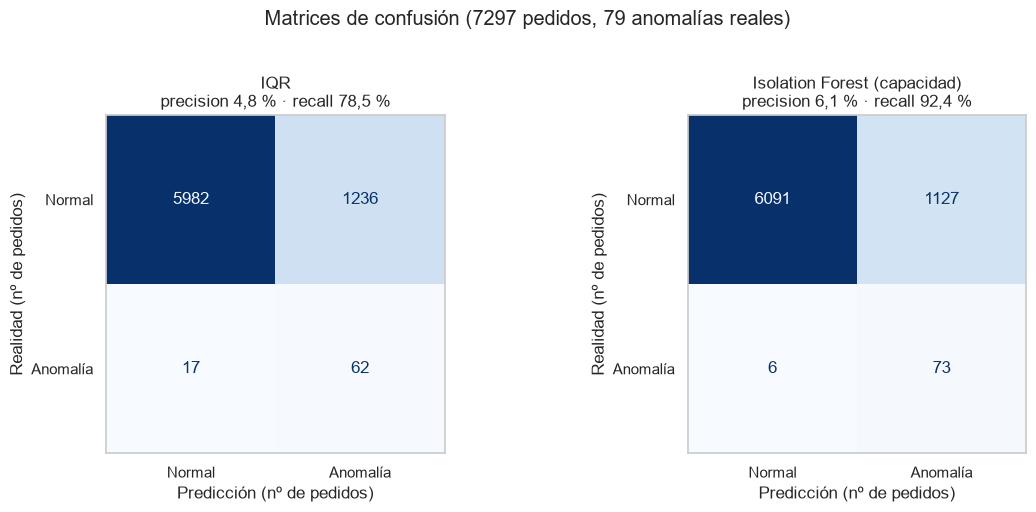

In [24]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, columna) in zip(ejes, [("IQR", "marcado_iqr"), ("Isolation Forest (capacidad)", "marcado")]):
    matriz = confusion_matrix(y, evaluacion[columna])
    ConfusionMatrixDisplay(matriz, display_labels=["Normal", "Anomalía"]).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                                values_format="d")
    ax.set_title(f"{nombre}\nprecision {pct(precision_score(y, evaluacion[columna]))} · "
                 f"recall {pct(recall_score(y, evaluacion[columna]))}")
    ax.set_xlabel("Predicción (nº de pedidos)")
    ax.set_ylabel("Realidad (nº de pedidos)")
    ax.grid(False)
fig.suptitle(f"Matrices de confusión ({len(y)} pedidos, {y.sum()} anomalías reales)", y=1.02)
fig.tight_layout()
guardar(fig, "matrices_confusion")
plt.show()

**Lectura:** el **accuracy no sirve**. No marcar nada da un 98,92 %, más que cualquiera de los tres
métodos (82,8 %, 84,5 % y 77,5 %), y no encuentra ni una anomalía. Con un 1,08 % de anomalías, el
accuracy premia ignorarlas.

- **Isolation Forest (capacidad)** encuentra **73 de 79 (recall 92,4 %)** con 1.200 alertas
  (precision 6,1 %, F1 0,114).
- **IQR** encuentra **62 de 79 (recall 78,5 %)** con 1.298 alertas (precision 4,8 %, F1 0,090).

Con menos alertas, Isolation Forest encuentra 11 anomalías más. La precision es baja en los dos porque
la capacidad (1.200 pedidos) es mucho mayor que el número de anomalías (79): aunque las 79 estuvieran
arriba del todo, la precision máxima sería 79 / 1.200 = 6,6 %. Isolation Forest se queda en 6,1 %, muy
cerca de ese techo.

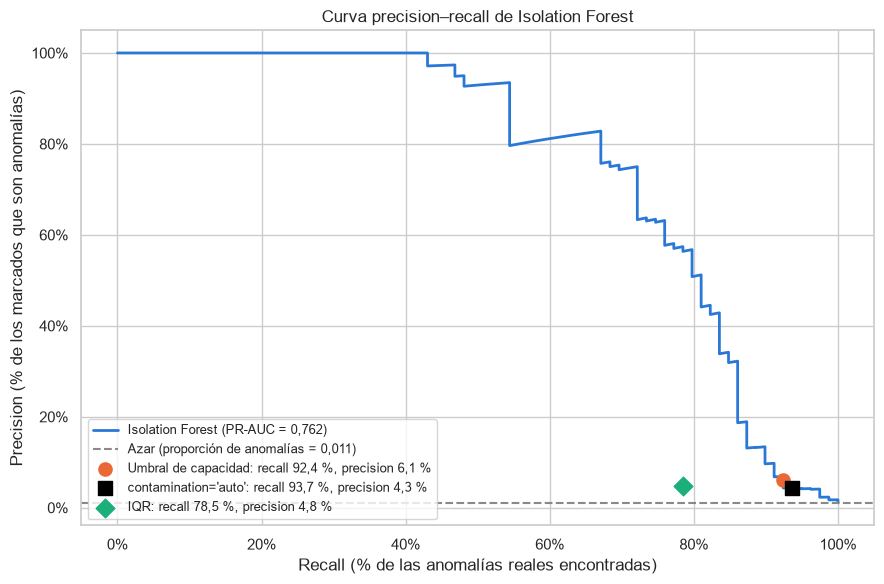

In [25]:
precision_c, recall_c, _ = precision_recall_curve(y, evaluacion["puntuacion"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(recall_c, precision_c, color=AZUL, linewidth=2, label=f"Isolation Forest (PR-AUC = {num(ap, 3)})")
ax.axhline(prevalencia, color=GRIS, linestyle="--", label=f"Azar (proporción de anomalías = {num(prevalencia, 3)})")
puntos_pr = [
    ("Umbral de capacidad", tabla_metricas.iloc[1], NARANJA, "o"),
    ("contamination='auto'", tabla_metricas.iloc[2], "black", "s"),
    ("IQR", tabla_metricas.iloc[0], VERDE_AGUA, "D"),
]
for nombre, fila, color, marcador in puntos_pr:
    ax.scatter(fila["recall"], fila["precision"], color=color, marker=marcador, s=90, zorder=3,
               label=f"{nombre}: recall {pct(fila['recall'])}, precision {pct(fila['precision'])}")
ax.set_xlabel("Recall (% de las anomalías reales encontradas)")
ax.set_ylabel("Precision (% de los marcados que son anomalías)")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Curva precision–recall de Isolation Forest")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
guardar(fig, "precision_recall")
plt.show()

**Lectura:** **ROC-AUC = 0,968** y **PR-AUC = 0,762**, frente a 0,011 del azar. La curva se queda en
el 100 % de precision hasta el 43,0 % de recall: los 34 primeros pedidos del ranking son todos
anomalías. Después baja a escalones, y las últimas anomalías solo se alcanzan con una precision muy
baja: tienen puntuaciones parecidas a las de muchos pedidos normales. El umbral de capacidad (naranja) está en
la parte de recall alto y precision baja, porque la capacidad es grande. IQR (verde) queda por debajo de
la curva: con su número de alertas, Isolation Forest encuentra más anomalías.

### Recall por tipo de anomalía

In [26]:
TIPOS = ["cantidad_enorme", "precio_alto", "precio_bajo", "muchas_lineas"]
anomalias = evaluacion[y]


def recall_por_tipo(columna_marcado):
    return anomalias.groupby("tipo_anomalia")[columna_marcado].mean().reindex(TIPOS)


evaluacion["top50"] = evaluacion["ranking"] <= 50
anomalias = evaluacion[y]
por_tipo = pd.DataFrame({
    "anomalías": anomalias["tipo_anomalia"].value_counts().reindex(TIPOS),
    "recall IQR": recall_por_tipo("marcado_iqr"),
    "recall IForest (capacidad)": recall_por_tipo("marcado"),
    "recall IForest (top 50)": recall_por_tipo("top50"),
    "ranking mediano": anomalias.groupby("tipo_anomalia")["ranking"].median().reindex(TIPOS),
    "ranking peor": anomalias.groupby("tipo_anomalia")["ranking"].max().reindex(TIPOS),
})
por_tipo.round(3)

,anomalías,recall IQR,recall IForest (capacidad),recall IForest (top 50),ranking mediano,ranking peor
tipo_anomalia,,,,,,
cantidad_enorme,25,1.000,1.000,1.000,14.0,37
precio_alto,8,1.000,0.500,0.000,1008.5,4541
precio_bajo,19,0.105,0.895,0.053,146.0,1780
muchas_lineas,27,1.000,1.000,0.630,43.0,111


In [27]:
# Las anomalías que se le escapan al umbral de capacidad, con sus variables
escapadas = anomalias[~anomalias["marcado"]]
print(f"Anomalías no marcadas: {len(escapadas)}")
escapadas[["id_pedido", "tipo_anomalia", "ranking", "puntuacion"] + VARIABLES].round(3)

Anomalías no marcadas: 6


,id_pedido,tipo_anomalia,ranking,puntuacion,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad
851,924,precio_bajo,1684,0.501,71.39,2,3,2,1.000,0.105,23.797
1365,1465,precio_alto,4541,0.433,115.40,2,3,2,8.249,1.000,38.467
1402,1504,precio_bajo,1780,0.497,72.12,2,3,2,1.000,0.127,24.040
1700,1831,precio_alto,3346,0.453,89.64,2,2,1,5.152,1.000,44.820
2625,2820,precio_alto,1878,0.494,192.18,3,6,3,7.801,1.000,32.030
6148,6640,precio_alto,1806,0.497,306.84,3,5,3,6.860,1.000,61.368


In [28]:
# Cada árbol se entrena con 256 pedidos al azar (max_samples). ¿Qué parte de los árboles no ve NINGÚN
# pedido con el precio distinto del catálogo? En esos árboles el ratio vale 1 en todos los pedidos y no
# se puede cortar por él.
n_muestra = pipeline.named_steps["iforest"].max_samples_
for nombre, cuantos in [("por encima", (pedidos["ratio_precio_max"] > 1.001).sum()),
                        ("por debajo", (pedidos["ratio_precio_min"] < 0.999).sum())]:
    sin_ninguno = (1 - cuantos / len(pedidos)) ** n_muestra
    print(f"Precio {nombre} del catálogo: {cuantos} pedidos → {pct(sin_ninguno)} de los árboles no ven ninguno "
          f"(muestra de {n_muestra})")
arboles = pipeline.named_steps["iforest"].estimators_
columnas_arbol = pipeline.named_steps["iforest"].estimators_features_
posicion = {v: i for i, v in enumerate(VARIABLES_LOG1P + VARIABLES_RATIO)}
for v in VARIABLES_RATIO:
    usan = np.mean([(columnas[arbol.tree_.feature[arbol.tree_.feature >= 0]] == posicion[v]).any()
                    for arbol, columnas in zip(arboles, columnas_arbol)])
    print(f"Árboles que cortan al menos una vez por {v}: {pct(usan)}")

# Cómo son las anomalías de cada tipo frente a los pedidos normales (medianas)
perfil = evaluacion.assign(grupo=evaluacion["tipo_anomalia"].fillna("normal")).groupby("grupo")[VARIABLES + ["puntuacion"]].median()
perfil.reindex(["normal"] + TIPOS).round(2)

Precio por encima del catálogo: 8 pedidos → 75,5 % de los árboles no ven ninguno (muestra de 256)
Precio por debajo del catálogo: 19 pedidos → 51,3 % de los árboles no ven ninguno (muestra de 256)
Árboles que cortan al menos una vez por ratio_precio_max: 25,7 %
Árboles que cortan al menos una vez por ratio_precio_min: 33,3 %


,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad,puntuacion
grupo,,,,,,,,
normal,82.34,1.0,2.0,2.0,1.00,1.00,39.66,0.45
cantidad_enorme,1736.16,1.0,47.0,47.0,1.00,1.00,44.88,0.72
precio_alto,249.51,2.0,2.5,2.0,8.03,1.00,98.83,0.54
precio_bajo,24.26,2.0,2.0,2.0,1.00,0.16,13.04,0.60
muchas_lineas,745.13,10.0,16.0,3.0,1.00,1.00,49.61,0.67


**Lectura:** 

| Tipo | Recall IQR | Recall IForest | Por qué |
|---|---:|---:|---|
| Cantidad enorme (25) | 100 % | **100 %** | La más fácil: 47 unidades de mediana frente a 2. Ranking mediano 14, el peor 37 |
| Muchas líneas (27) | 100 % | **100 %** | 10 líneas de mediana frente a 1. Ranking mediano 43, el peor 111 |
| Precio bajo (19) | 10,5 % | **89,5 %** | El ratio mínimo (×0,16 de mediana) y el importe por unidad, que baja de 39,66 € a 13,04 €. IQR no las ve porque solo mira hacia arriba |
| Precio alto (8) | **100 %** | 50 % | Se le escapan 4 de 8 (ranking mediano 1.008,5, el peor 4.541) |

**Por qué se escapan los precios altos:**

1. **El ratio es una variable casi constante.** Solo 8 de 7.297 pedidos tienen el precio por encima del
   catálogo, y cada árbol se entrena con 256 pedidos al azar: el **75,5 % de los árboles no ve ninguno**.
   En esos árboles el ratio vale 1 en todos los pedidos y no se puede cortar por él. Solo el 25,7 % de
   los árboles corta alguna vez por `ratio_precio_max`, y por eso un sobreprecio ×8 se aísla menos de lo
   que debería.
2. **Las otras variables no lo delatan.** Las 4 que se escapan son pedidos de 2–3 líneas en los que solo
   una línea tiene el sobreprecio: importe de 89,64 € a 306,84 € e importe por unidad de 32,03 € a
   61,37 €, valores normales.
3. **IQR los encuentra todos por casualidad del límite:** con Q1 = Q3 = 1, el límite es 1 y cualquier
   precio por encima del catálogo cuenta como outlier.

Las 2 de precio bajo que se escapan son parecidas (2 líneas, una con ×0,11–×0,13) y se quedan justo
por debajo del umbral (0,501 y 0,497 frente a 0,529).

### Precision@50 y recall@50

In [29]:
top50 = evaluacion[evaluacion["top50"]]
precision_50 = top50["es_anomalia"].mean()
recall_50 = top50["es_anomalia"].sum() / y.sum()
print(f"De los 50 pedidos más sospechosos, {top50['es_anomalia'].sum()} son anomalías reales")
print(f"Precision@50 = {pct(precision_50)} · recall@50 = {pct(recall_50)}")
primer_falso = evaluacion.loc[~y, "ranking"].min()
print(f"El primer pedido que NO es anomalía está en el puesto {primer_falso}: los {primer_falso - 1} primeros "
      f"son todos anomalías ({pct((primer_falso - 1) / y.sum())} de las {y.sum()})")
for k in [25, 79, 100, 200]:
    print(f"  top {k:>3}: {evaluacion.loc[evaluacion['ranking'] <= k, 'es_anomalia'].sum()} anomalías")

De los 50 pedidos más sospechosos, 43 son anomalías reales
Precision@50 = 86,0 % · recall@50 = 54,4 %
El primer pedido que NO es anomalía está en el puesto 35: los 34 primeros son todos anomalías (43,0 % de las 79)
  top  25: 25 anomalías
  top  79: 57 anomalías
  top 100: 60 anomalías
  top 200: 67 anomalías


**Lectura:** de los 50 pedidos más sospechosos, **43 son anomalías reales (precision@50 = 86,0 %)**,
el 54,4 % de todas (recall@50). Los 25 primeros son todos anomalías, y en el top 100 hay 60. Si el
equipo empieza a revisar por el principio del ranking, casi todo lo que mira al principio es un
problema real: el orden importa más que el umbral.

### Los falsos positivos más altos

In [30]:
falsos = evaluacion[~y].nsmallest(10, "ranking")
falsos_tabla = falsos[["ranking", "id_pedido", "estado", "puntuacion"] + VARIABLES + ["motivo_principal"]].round(3)
falsos_tabla

,ranking,id_pedido,estado,puntuacion,importe_total,n_lineas,unidades_totales,max_cantidad_linea,ratio_precio_max,ratio_precio_min,importe_por_unidad,motivo_principal
980,35,1057,completado,0.677,1472.30,4,10,5,1.0,1.0,147.230,Muchas líneas: 4 (mediana 1)
1947,39,2091,completado,0.673,1259.13,4,11,5,1.0,1.0,114.466,Muchas líneas: 4 (mediana 1)
5997,41,6480,completado,0.670,1232.74,4,9,5,1.0,1.0,136.971,Muchas líneas: 4 (mediana 1)
1040,47,1119,completado,0.659,1251.91,3,9,5,1.0,1.0,139.101,Importe alto: 1.252 € (mediana 84 €)
4420,48,4768,completado,0.658,1082.25,1,5,5,1.0,1.0,216.450,Importe por unidad alto: 216 € (mediana 40 €)
6198,49,6692,cancelado,0.658,1082.25,1,5,5,1.0,1.0,216.450,Importe por unidad alto: 216 € (mediana 40 €)
6597,50,7139,completado,0.658,1082.25,1,5,5,1.0,1.0,216.450,Importe por unidad alto: 216 € (mediana 40 €)
1658,51,1785,completado,0.658,1086.15,1,5,5,1.0,1.0,217.230,Importe por unidad alto: 217 € (mediana 40 €)
5686,52,6142,completado,0.658,1086.15,1,5,5,1.0,1.0,217.230,Importe por unidad alto: 217 € (mediana 40 €)
6456,53,6978,cancelado,0.658,1086.15,1,5,5,1.0,1.0,217.230,Importe por unidad alto: 217 € (mediana 40 €)


In [31]:
# Para cada falso positivo: cuántos pedidos igualan o superan su variable más rara, y cuántos tienen
# un importe igual o mayor (¿es raro por una variable o por la combinación?)
for _, fila in falsos.iterrows():
    v = fila["variable_motivo"]
    if fila["desviacion_motivo"] > 0:
        iguales = (pedidos[v] >= fila[v]).sum()
        sentido = "≥"
    else:
        iguales = (pedidos[v] <= fila[v]).sum()
        sentido = "≤"
    print(f"Ranking {fila['ranking']:>3} · pedido {fila['id_pedido']:>5}: {fila['motivo_principal']:<45} "
          f"→ {iguales} pedidos con {v} {sentido} {num(fila[v], 2)}; "
          f"{(pedidos['importe_total'] >= fila['importe_total']).sum()} con importe ≥ {euros(fila['importe_total'])}")

Ranking  35 · pedido  1057: Muchas líneas: 4 (mediana 1)                  → 380 pedidos con n_lineas ≥ 4,00; 18 con importe ≥ 1.472 €
Ranking  39 · pedido  2091: Muchas líneas: 4 (mediana 1)                  → 380 pedidos con n_lineas ≥ 4,00; 20 con importe ≥ 1.259 €
Ranking  41 · pedido  6480: Muchas líneas: 4 (mediana 1)                  → 380 pedidos con n_lineas ≥ 4,00; 23 con importe ≥ 1.233 €
Ranking  47 · pedido  1119: Importe alto: 1.252 € (mediana 84 €)          → 21 pedidos con importe_total ≥ 1.251,91; 21 con importe ≥ 1.252 €
Ranking  48 · pedido  4768: Importe por unidad alto: 216 € (mediana 40 €) → 158 pedidos con importe_por_unidad ≥ 216,45; 39 con importe ≥ 1.082 €
Ranking  49 · pedido  6692: Importe por unidad alto: 216 € (mediana 40 €) → 158 pedidos con importe_por_unidad ≥ 216,45; 39 con importe ≥ 1.082 €
Ranking  50 · pedido  7139: Importe por unidad alto: 216 € (mediana 40 €) → 158 pedidos con importe_por_unidad ≥ 216,45; 39 con importe ≥ 1.082 €
Ranking  51 · pedi

**Lectura:** los falsos positivos más altos **sí son pedidos raros**, aunque no se plantaran:

- **Puestos 35, 39 y 41:** pedidos de 4 líneas con 9–11 unidades y 1.232–1.472 €. Hay 380 pedidos con 4
  líneas, pero solo entre 18 y 23 con ese importe o más. Lo raro es la **combinación**: grande en
  líneas, unidades e importe a la vez.
- **Puestos 48 a 53:** 5 unidades del producto más caro (216,45 € y 217,23 € la unidad), 1.082–1.086 €.
  Solo 36–39 pedidos tienen ese importe o más. Son pedidos idénticos entre sí (mismo producto y cantidad)
  y por eso tienen la misma puntuación; el empate se resuelve por `id_pedido`.

Son pedidos que un equipo de revisión querría mirar igualmente: más de 1.000 € en un pedido cuando la
mediana es de 83,90 €. La parte "mala" es que el motivo de los puestos 35–41 ("4 líneas") explica mal
la alerta: el modelo los marca por la combinación, y el motivo solo muestra una variable.

## 8. EVALUACIÓN · Ablación: ¿qué aportan los ratios de precio?

> **Análisis a posteriori** (usa la verdad): no sirve para elegir el modelo, que ya está elegido y
> guardado. Sirve para entender qué variable aporta qué.

Se quita `ratio_precio_max` y `ratio_precio_min`, se entrena el mismo modelo con las otras 5 variables
y el mismo criterio de umbral (el mismo % de pedidos), y se compara.

In [32]:
VARIABLES_SIN_RATIO = [v for v in VARIABLES if not v.startswith("ratio")]
ablacion = crear_pipeline(VARIABLES_LOG1P, []).fit(pedidos[VARIABLES_SIN_RATIO])
evaluacion["puntuacion_sin_ratio"] = puntuar(ablacion, pedidos[VARIABLES_SIN_RATIO])
umbral_sin_ratio = float(np.quantile(evaluacion["puntuacion_sin_ratio"], 1 - pct_capacidad))
evaluacion["marcado_sin_ratio"] = evaluacion["puntuacion_sin_ratio"] >= umbral_sin_ratio
evaluacion["ranking_sin_ratio"] = evaluacion["puntuacion_sin_ratio"].rank(ascending=False, method="first")
anomalias = evaluacion[y]


def resumen_modelo(nombre, puntuacion, marcado, ranking):
    return {
        "modelo": nombre,
        "marcados": int(marcado.sum()),
        "precision": precision_score(y, marcado),
        "recall": recall_score(y, marcado),
        "F1": f1_score(y, marcado),
        "ROC-AUC": roc_auc_score(y, puntuacion),
        "PR-AUC": average_precision_score(y, puntuacion),
        "precision@50": evaluacion.loc[ranking <= 50, "es_anomalia"].mean(),
    }


tabla_ablacion = pd.DataFrame([
    resumen_modelo("Completo (7 variables)", evaluacion["puntuacion"], evaluacion["marcado"], evaluacion["ranking"]),
    resumen_modelo("Sin ratios de precio (5 variables)", evaluacion["puntuacion_sin_ratio"],
                   evaluacion["marcado_sin_ratio"], evaluacion["ranking_sin_ratio"]),
]).set_index("modelo")
tabla_ablacion.round(3)

,marcados,precision,recall,F1,ROC-AUC,PR-AUC,precision@50
modelo,,,,,,,
Completo (7 variables),1200,0.061,0.924,0.114,0.968,0.762,0.86
Sin ratios de precio (5 variables),1200,0.055,0.835,0.103,0.928,0.671,0.82


In [33]:
evaluacion["top50_sin_ratio"] = evaluacion["ranking_sin_ratio"] <= 50
anomalias = evaluacion[y]
por_tipo_ablacion = pd.DataFrame({
    "completo (capacidad)": recall_por_tipo("marcado"),
    "sin ratios (capacidad)": recall_por_tipo("marcado_sin_ratio"),
    "completo: ranking mediano": anomalias.groupby("tipo_anomalia")["ranking"].median().reindex(TIPOS),
    "sin ratios: ranking mediano": anomalias.groupby("tipo_anomalia")["ranking_sin_ratio"].median().reindex(TIPOS),
})
por_tipo_ablacion.round(3)

,completo (capacidad),sin ratios (capacidad),completo: ranking mediano,sin ratios: ranking mediano
tipo_anomalia,,,,
cantidad_enorme,1.000,1.000,14.0,14.0
precio_alto,0.500,0.500,1008.5,1521.5
precio_bajo,0.895,0.526,146.0,1102.0
muchas_lineas,1.000,1.000,43.0,42.0


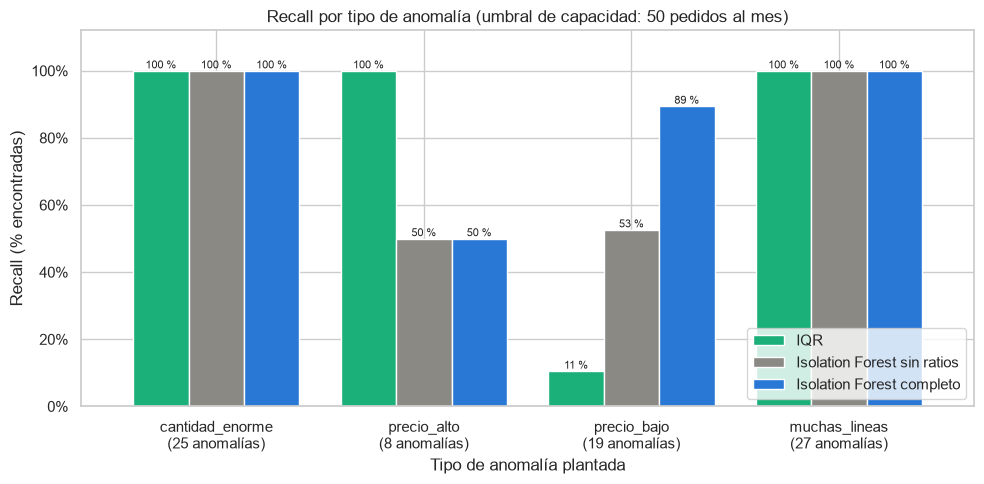

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
recalls = pd.DataFrame({
    "IQR": por_tipo["recall IQR"],
    "Isolation Forest sin ratios": por_tipo_ablacion["sin ratios (capacidad)"],
    "Isolation Forest completo": por_tipo["recall IForest (capacidad)"],
})
recalls.index = [f"{t}\n({n} anomalías)" for t, n in por_tipo["anomalías"].items()]
recalls.plot.bar(ax=ax, color=[VERDE_AGUA, GRIS, AZUL], rot=0, width=0.8)
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[pct(v, 0) for v in contenedor.datavalues], fontsize=8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.12)
ax.set_xlabel("Tipo de anomalía plantada")
ax.set_ylabel("Recall (% encontradas)")
ax.set_title("Recall por tipo de anomalía (umbral de capacidad: 50 pedidos al mes)")
ax.legend(loc="lower right")
fig.tight_layout()
guardar(fig, "recall_por_tipo")
plt.show()

**Lectura:** quitar los ratios de precio empeora todas las métricas: recall del 92,4 % al 83,5 %,
F1 de 0,114 a 0,103, ROC-AUC de 0,968 a 0,928, **PR-AUC de 0,762 a 0,671** y precision@50 del 86 % al 82 %.
Casi todo viene de los **precios bajos: el recall cae del 89,5 % al 52,6 %** y su ranking mediano pasa
del 146 al 1.102. Cantidad enorme y muchas líneas no cambian (100 %): ya los delatan las unidades y las
líneas. En los precios altos el recall se queda en 50 % con y sin ratios; sin ellos, el ranking mediano
empeora de 1.008,5 a 1.521,5.

**Qué demuestra:** el algoritmo no inventa información. Un precio distinto del catálogo solo se puede
detectar si alguna variable **compara el precio con el catálogo**; sin ella, el modelo solo ve el
efecto indirecto en el importe por unidad. Crear la variable adecuada (una división en SQL) aporta más
que cualquier ajuste de hiperparámetros. Y el caso de los precios altos muestra el límite contrario:
una variable que casi nunca cambia (8 pedidos de 7.297) es difícil de usar para Isolation Forest,
aunque sea la buena.

## 9. Conclusiones

1. **Hay pedidos sospechosos y se pueden ordenar.** Isolation Forest da a cada pedido una puntuación
   de 0 a 1 (de 0,401 a 0,752) y un motivo en palabras ("59 unidades en un pedido; mediana 2").
2. **Umbral de negocio: s ≥ 0,529**, que corresponde a revisar 50 pedidos al mes (16,45 %, 1.200
   pedidos). `contamination="auto"` marcaba 1.710 (71,2 al mes) y superaba la capacidad todos los meses.
   En 11 de 24 meses el umbral fijo da más de 50 alertas (máximo 74): esos meses se revisa por ranking.
3. **Isolation Forest supera a IQR con menos alertas:** recall del 92,4 % frente al 78,5 % (73 frente a
   62 de 79 anomalías), precision del 6,1 % frente al 4,8 % y F1 de 0,114 frente a 0,090. Con la
   puntuación continua, ROC-AUC = 0,968 y PR-AUC = 0,762 (azar = 0,011).
4. **El ranking es lo más valioso:** de los 50 pedidos más sospechosos, 43 son anomalías reales
   (precision@50 = 86,0 %) y los 34 primeros lo son todos.
5. **Por tipo:** encuentra el 100 % de las cantidades enormes y de los pedidos con muchas líneas, el
   89,5 % de los precios bajos y solo el 50 % de los precios altos. Un sobreprecio en una sola línea
   apenas cambia las demás variables, y el 75,5 % de los árboles no ve ningún pedido con el precio por
   encima del catálogo.
6. **Las variables importan más que el algoritmo:** sin los ratios de precio, la PR-AUC baja de 0,762
   a 0,671 y el recall de precios bajos del 89,5 % al 52,6 %.
7. **Es estable:** con otras 5 semillas, el 92,5–95,8 % de los marcados coincide (Jaccard medio 0,895)
   y del top 50 coinciden 46 o 47.

**Respuesta a la pregunta de negocio:** son sospechosos los pedidos con muchas unidades de un mismo
producto, con muchas líneas o con un precio lejos del de catálogo. `data/processed/pedidos_sospechosos.csv`
da los 1.200 marcados (50 al mes) ordenados por sospecha y con su motivo. Hay que revisarlos **por
orden de ranking**: al principio de la lista casi todo es un problema real.

**Trabajo futuro (no aplicado):** solo 27 pedidos (0,37 %) tienen un precio distinto del de
catálogo, así que una **regla simple** ("precio ≠ catálogo → revisar") junto al modelo cubriría los precios
altos que se le escapan. La idea sale de la evaluación con la verdad (secciones 7 y 8), así que no se ha
cambiado el modelo, igual que en la S7: el modelo se eligió sin la verdad y así se queda.